In [101]:
import json
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor
import threading
import os
from datetime import datetime

import cv2
import  numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../../../db/obj-det/color_data/tst.csv")
df.head()

,avi_path,camera_type,seq_name,frame_n,frame_h,frame_w,x_left,y_top,width,height
0,/mnt/pg-fs01/Current/DB/CV_PeopleTracking/Vide...,SPCA2281B-L0,ILoffice_H250_Cam2_MR_VLC_4HO_20fps_r1_2022060...,170,480,640,398,179,126,58
1,/mnt/pg-fs01/Current/DB/CV_PeopleTracking/Vide...,SPCA2281B-L0,ILoffice_H250_Cam2_MR_VLC_4HO_20fps_r1_2022060...,171,480,640,399,178,133,59
2,/mnt/pg-fs01/Current/DB/CV_PeopleTracking/Vide...,SPCA2281B-L0,ILoffice_H250_Cam2_MR_VLC_4HO_20fps_r1_2022060...,172,480,640,399,178,158,59
3,/mnt/pg-fs01/Current/DB/CV_PeopleTracking/Vide...,SPCA2281B-L0,ILoffice_H250_Cam2_MR_VLC_4HO_20fps_r1_2022060...,173,480,640,396,175,163,62
4,/mnt/pg-fs01/Current/DB/CV_PeopleTracking/Vide...,SPCA2281B-L0,ILoffice_H250_Cam2_MR_VLC_4HO_20fps_r1_2022060...,174,480,640,394,173,168,64


In [61]:
def get_frames(avi_path, frame_nums):
    frames = {}
    count = 0
    cap = cv2.VideoCapture(avi_path)
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if count in frame_nums:
            frames[count] = frame
        count += 1

    cap.release()
    return frames

In [70]:
N = 10
M = 10000

images = []
annotations = []

avi_idx = 0

avi_paths = df.avi_path.unique()
for avi_path in avi_paths[1:2]:
    avi_name = avi_path.split("/")[-1].replace(".avi", "")

    avi_df = df[df["avi_path"] == avi_path]
    frame_numbers = avi_df["frame_n"].unique()[::N]
    camera_type = avi_df["camera_type"].values[0]
    w = avi_df["frame_w"].values[0]
    h = avi_df["frame_h"].values[0]
    
    frames = get_frames(avi_path, frame_numbers)
    for frame_n in tqdm(frame_numbers):
        img_name = f"{avi_name}__{frame_n}.jpg"
        img_id = int(avi_idx * M + frame_n)

        images.append({
            "id": img_id,
            "license": None,
            "coco_url": None,
            "flickr_url": None,
            "width": int(w),
            "height": int(h),
            "file_name": img_name,
            "date_captured": str(datetime.now())
        })

        frame_df = avi_df[avi_df["frame_n"] == frame_n]

        img = frames[frame_n]
        axis = (1)
        if camera_type in ["SPCA2281B-L0", "SPCA2281B-L1"]:
            axis=(0, 1)

        img = np.flip(img, axis=axis).astype(np.uint8)

        for idx, row in frame_df.iterrows():
            # cv2.rectangle(img, (row["x_left"], row["y_top"]), (row["x_left"] + row["width"], row["y_top"] + row["height"]), (255, 0, 0), 2)
            annotations.append({
                "id": img_id * M + idx, 
                "image_id": img_id,
                "category_id": 0,
                "segmentation": None, 
                "area": None, 
                "bbox": [int(i) for i in [row["x_left"], row["y_top"], row["width"], row["height"]]], 
                "iscrowd": None,
            })

        cv2.imwrite(os.path.join("tmp_dataset/frames", img_name), img)

100%|██████████| 335/335 [00:02<00:00, 113.12it/s]


In [71]:
with open("tmp_dataset/labels.json", "wt") as f:
    json.dump({
        "info": {"description": ""},
        "licenses": [],
        "images": images,
        "annotations": annotations,
        "categories": [
            {"supercategory": None,"id": 0,"name": "person"},
        ]
    }, f)

In [72]:
from pycocotools.coco import COCO

gt = COCO("tmp_dataset/labels.json")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


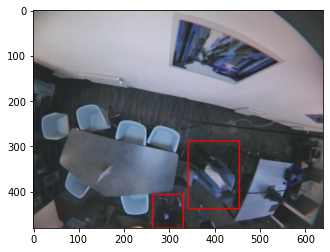

In [74]:


# Random idx
random_image = 5 #np.random.randint(0,len(train_df))
# Get image ID
img_id = list(gt.imgs)[random_image]
# Read image
img = cv2.imread(os.path.join("tmp_dataset/frames", gt.imgs[img_id]["file_name"]))

for ann_id in gt.getAnnIds(imgIds = [img_id]):
    ann_item = gt.anns[ann_id]
    bbox = ann_item["bbox"]
    cv2.rectangle(img, bbox[:2], (bbox[0] + bbox[2], bbox[1] + bbox[3]), (255, 0, 0), 2)

plt.imshow(img)

In [104]:
def process_avi_file(in_data):
    df = pd.read_csv("../../../db/obj-det/color_data/tst.csv")

    avi_path, avi_idx = in_data
    out = ""
    images = []
    annotations = []
    try:
        avi_name = avi_path.split("/")[-1].replace(".avi", "")

        avi_df = df[df["avi_path"] == avi_path]
        frame_numbers = avi_df["frame_n"].unique()[::N]
        camera_type = avi_df["camera_type"].values[0]
        w = avi_df["frame_w"].values[0]
        h = avi_df["frame_h"].values[0]
        
        frames = get_frames(avi_path, frame_numbers)
        for frame_n in frame_numbers:
            img_name = f"{avi_name}__{frame_n}.jpg"
            img_id = int(avi_idx * M + frame_n)

            images.append({
                "id": img_id,
                "license": None,
                "coco_url": None,
                "flickr_url": None,
                "width": int(w),
                "height": int(h),
                "file_name": img_name,
                "date_captured": str(datetime.now())
            })

            frame_df = avi_df[avi_df["frame_n"] == frame_n]

            img = frames[frame_n]
            axis = (1)
            if camera_type in ["SPCA2281B-L0", "SPCA2281B-L1"]:
                axis=(0, 1)

            img = np.flip(img, axis=axis).astype(np.uint8)

            for idx, row in frame_df.iterrows():
                # cv2.rectangle(img, (row["x_left"], row["y_top"]), (row["x_left"] + row["width"], row["y_top"] + row["height"]), (255, 0, 0), 2)
                annotations.append({
                    "id": img_id * M + idx, 
                    "image_id": img_id,
                    "category_id": 0,
                    "segmentation": None, 
                    "area": None, 
                    "bbox": [int(i) for i in [row["x_left"], row["y_top"], row["width"], row["height"]]], 
                    "iscrowd": None,
                })

            cv2.imwrite(os.path.join("tmp_dataset/frames", img_name), img)
    except Exception as e:
        out = f"{avi_path} - {e}\n"
    return images, annotations, out


In [108]:
_ = [process_avi_file((i, idx)) for idx, i in enumerate(avi_paths[:5])]

In [109]:
def run(f, my_iter):
    with ThreadPoolExecutor(max_workers=4) as executor:
        results = list(tqdm(executor.map(f, my_iter), total=len(my_iter)))
    return results

avi_data = [(i, idx) for idx, i in enumerate(avi_paths)]

results = run(process_avi_file, avi_data[:5])

100%|██████████| 5/5 [04:03<00:00, 48.66s/it] 


In [110]:
def run(f, my_iter):
    with ProcessPoolExecutor(max_workers=4) as executor:
        results = list(tqdm(executor.map(f, my_iter), total=len(my_iter)))
    return results

avi_data = [(i, idx) for idx, i in enumerate(avi_paths)]

results = run(process_avi_file, avi_data[:5])

100%|██████████| 5/5 [03:50<00:00, 46.08s/it] 


In [86]:
imgs = []
annot = []
errors = []
for i in results:
    imgs += i[0]
    annot += i[1]
    errors.append(i[2])

In [93]:
with open("tmp_dataset/labels3.json", "wt") as f:
    json.dump({
        "info": {"description": ""},
        "licenses": [],
        "images": imgs,
        "annotations": annot,
        "categories": [
            {"supercategory": None,"id": 0,"name": "person"},
        ]
    }, f)

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


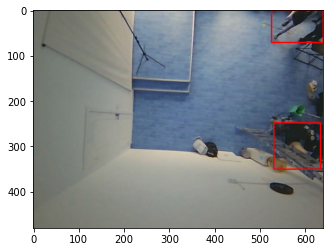

In [96]:
from pycocotools.coco import COCO

gt = COCO("tmp_dataset/labels3.json")



# Random idx
random_image = 700 #np.random.randint(0,len(train_df))
# Get image ID
img_id = list(gt.imgs)[random_image]
# Read image
img = cv2.imread(os.path.join("tmp_dataset/frames", gt.imgs[img_id]["file_name"]))

for ann_id in gt.getAnnIds(imgIds = [img_id]):
    ann_item = gt.anns[ann_id]
    bbox = ann_item["bbox"]
    cv2.rectangle(img, bbox[:2], (bbox[0] + bbox[2], bbox[1] + bbox[3]), (255, 0, 0), 2)

plt.imshow(img)